# 10 — Forecasting tomorrow's prices: through dispatch (Route B) or directly (Route A)

**Does:** forecasts tomorrow's price in every state two ways. **Route B** runs the Part 1 dispatch model on tomorrow's forecast demand and availability. **Route A** forecasts the price directly from its own history, calendar and weather. Also: which forecast error (demand or supply) causes most of the price error, price ranges, and a "tightness" index for Part 3.

**Question:** can tomorrow's price be forecast better than "same as today", and is the dispatch model worth it?

**Input:** `demand_forecast_dayahead.csv` (L6, real anchored forecasts), `availability_forecast_test.csv` ("best day-ahead"), `dispatch_weather_*_daily.csv` (the actual prices), Stage 3/4 inputs

**Output:** `data/processed/price_forecast_test.csv`

**Code:** `src/dispatch.py` (`run_all_days`), `src/forecast.py` (`jump_scores`, `available_capacity`, `tightness`, Route A models)

**Logged in:** `docs/model_log.md`, Step 18

## Design (Stage 5 decisions)

| Choice | Value |
|---|---|
| Route B runs | **actual** (actual demand and availability: reproduces the actual price), **realistic** (L6 demand with real day-ahead weather + best day-ahead availability), **demand error only** (forecast demand, actual availability), **supply error only** (actual demand, forecast availability), **persistence** (today's demand and availability = today's price) |
| Route A | The change ratio log(price_T / price_D) from recent price changes, weekday, month, holidays and anchored day-ahead weather; national model and one pooled model for the 32 states; persistence → profile → linear → LightGBM (mean and median); trained on actual weather, monthly walk-forward |
| Scoring | Mar 2024 – Mar 2025 (real forecasts exist). MAE (Rs/MWh) and skill vs persistence, target **≥ 0.20**; **jumps**: national moves of ≥ 200 Rs/MWh; recall = share of real jumps called in the right direction, precision = share of calls that were right |
| Ranges | Dispatch at the L6 **10% and 90% demand** forecasts (real day-ahead weather) |
| Tightness | (available MW − demand) ÷ demand, per state and India, actual and forecast |

National price = demand-weighted average of state prices (forecasts weighted by forecast demand).

In [1]:
import sys
sys.path.append("../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import weather as w
import features as F
import forecast as fc
from dispatch import (LossDispatchModel, daily_availability_lookup, load_coordinates, load_demand,
                      load_generators, loss_matrix, run_all_days, PROCESSED)

SCORE = slice("2024-03-01", "2025-03-31")
dates = pd.date_range(SCORE.start, SCORE.stop)
gen = load_generators()
demand = load_demand()
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)

actual_state = pd.read_csv(PROCESSED / "dispatch_weather_state_daily.csv", parse_dates=["Date"])
actual_nat = pd.read_csv(PROCESSED / "dispatch_weather_national_daily.csv", parse_dates=["Date"]).set_index("Date")
price = actual_state.pivot(index="Date", columns="State", values="Price")[states]
truth = actual_nat.Price_avg.loc[SCORE]
persistence = actual_nat.Price_avg.shift(1).loc[SCORE]

## 1. Inputs

In [2]:
act_avail = pd.read_csv(PROCESSED / "availability_daily.csv", parse_dates=["Date"])
afc = pd.read_csv(PROCESSED / "availability_forecast_test.csv", parse_dates=["Date"])
best_avail = afc[afc.Model == "best day-ahead"][["Date", "State", "Fuel_Type", "Forecast"]].rename(columns={"Forecast": "Factor"})
dfc = pd.read_csv(PROCESSED / "demand_forecast_dayahead.csv", parse_dates=["Date"])
demand_fc = dfc[(dfc.Model == "L6 LightGBM median") & (dfc.Weather == "day-ahead")].pivot(
    index="Date", columns="State", values="Forecast").reindex(dates)[states]
demand_act = demand.loc[SCORE]

assert demand_fc.notna().all().all()
assert best_avail[best_avail.Date.between(SCORE.start, SCORE.stop)].groupby("Date").size().eq(
    len(best_avail[best_avail.Date == SCORE.stop])).all()
print(f"{len(dates)} days; demand forecast for {demand_fc.shape[1]} states; "
      f"{best_avail[best_avail.Date == SCORE.stop].shape[0]} forecast state-fuel factors per day")

396 days; demand forecast for 32 states; 93 forecast state-fuel factors per day


## 2. Route B: the five runs

In [3]:
lookup_act = daily_availability_lookup(act_avail[act_avail.Date.between(SCORE.start, SCORE.stop)])
lookup_fc = daily_availability_lookup(best_avail[best_avail.Date.between(SCORE.start, SCORE.stop)])

runs, state_runs = {}, {}
for name, dem, lk in [("actual", demand_act, lookup_act), ("realistic", demand_fc, lookup_fc),
                      ("demand error only", demand_fc, lookup_act), ("supply error only", demand_act, lookup_fc)]:
    t = time.time()
    st, fl, nat = run_all_days(model, dem, daily=lk)
    runs[name] = nat.set_index("Date").Price_avg
    state_runs[name] = st.pivot(index="Date", columns="State", values="Price")[states]
    print(f"{name:18s} {time.time() - t:4.1f} s")

diff = (runs["actual"] - truth).abs()
print(f"actual run vs saved actual prices: max difference {diff.max():.2f} Rs/MWh (4-decimal rounding of saved factors)")
assert diff.max() < 1
runs["persistence"] = persistence
state_runs["persistence"] = price.shift(1).loc[SCORE]

actual              2.2 s


realistic           2.2 s


demand error only   2.1 s


supply error only   2.1 s
actual run vs saved actual prices: max difference 0.84 Rs/MWh (4-decimal rounding of saved factors)


In [4]:
base = (persistence - truth).abs().mean()
state_base = (state_runs["persistence"] - price.loc[SCORE]).abs().stack().mean()

def scores(national_fc, state_fc=None):
    e = (national_fc - truth.loc[national_fc.index]).abs()
    out = {"national MAE": e.mean(), "skill": 1 - e.mean() / base,
           "RMSE": np.sqrt(((national_fc - truth.loc[national_fc.index]) ** 2).mean())}
    j = fc.jump_scores(persistence.loc[national_fc.index], truth.loc[national_fc.index], national_fc)
    out.update({"jumps caught": f"{j['caught']}/{j['real jumps']}", "recall": j["recall"], "precision": j["precision"]})
    if state_fc is not None:
        se = (state_fc - price.loc[state_fc.index]).abs().stack().mean()
        out.update({"state MAE": se, "state skill": 1 - se / state_base})
    return out

route_b = pd.DataFrame({f"B: {k}": scores(v, state_runs[k]) for k, v in runs.items() if k != "actual"}).T
route_b.round(3)

,national MAE,skill,RMSE,jumps caught,recall,precision,state MAE,state skill
B: realistic,62.655844,0.526771,145.658655,58/87,0.666667,0.734177,63.738301,0.521424
B: demand error only,47.711824,0.639641,130.890902,66/87,0.758621,0.835443,49.234755,0.630323
B: supply error only,38.340971,0.710417,109.889429,68/87,0.781609,0.829268,38.251503,0.712791
B: persistence,132.400734,0.0,246.864351,0/87,0.0,NaN,133.183318,0.0


**Reading the decomposition:** "demand error only" and "supply error only" each switch on one forecast error. Their MAEs show how much each would cost alone; the realistic run has both (errors partly add up, partly cancel).

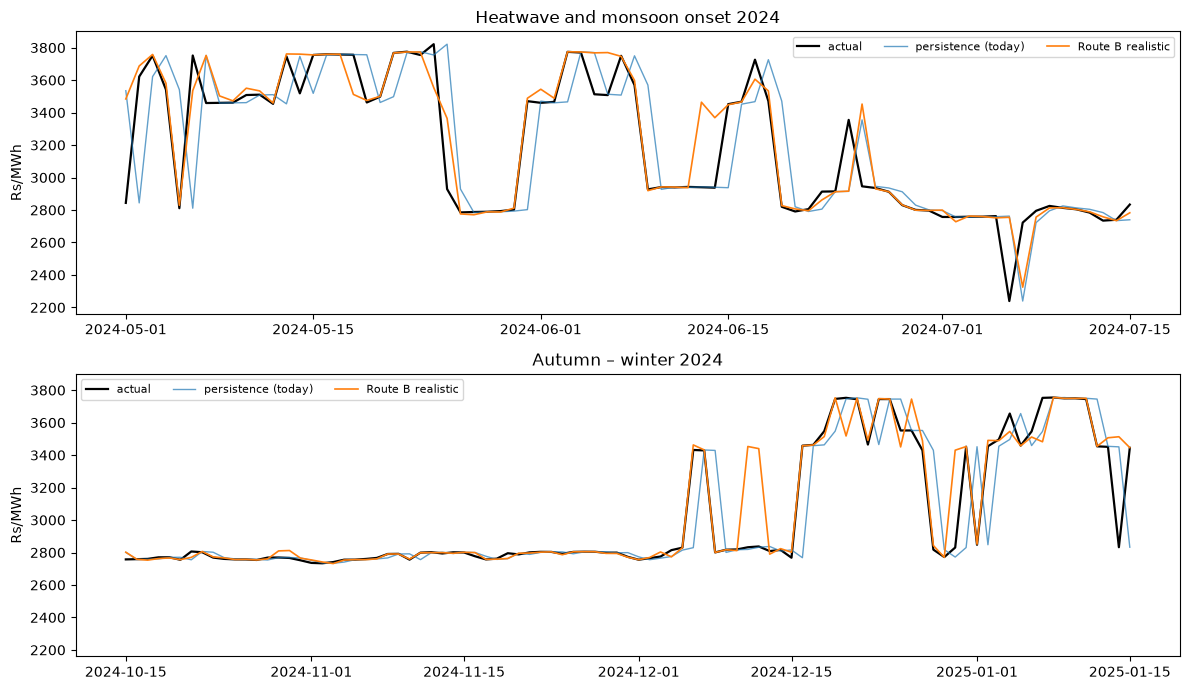

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=True)
for ax, window, title in [(axes[0], slice("2024-05-01", "2024-07-15"), "Heatwave and monsoon onset 2024"),
                          (axes[1], slice("2024-10-15", "2025-01-15"), "Autumn – winter 2024")]:
    ax.plot(truth.loc[window], color="black", lw=1.6, label="actual")
    ax.plot(persistence.loc[window], lw=1, alpha=0.7, label="persistence (today)")
    ax.plot(runs["realistic"].loc[window], lw=1.2, label="Route B realistic")
    ax.set_title(title); ax.set_ylabel("Rs/MWh"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
by_state = pd.DataFrame({
    "persistence MAE": (state_runs["persistence"] - price.loc[SCORE]).abs().mean(),
    "Route B MAE": (state_runs["realistic"] - price.loc[SCORE]).abs().mean()})
by_state["skill"] = 1 - by_state["Route B MAE"] / by_state["persistence MAE"]
by_state.sort_values("skill").round(2).T

State,West Bengal,Manipur,Arunachal Pradesh,Nagaland,NER Meghalaya,Assam,Mizoram,J&K(UT) & Ladakh(UT),Tripura,Sikkim,...,Goa,MP,ER Odisha,Rajasthan,Telangana,Puducherry,Chhattisgarh,Andhra Pradesh,Kerala,SR Karnataka
persistence MAE,128.63,133.32,131.03,132.74,132.86,132.83,133.13,142.22,131.68,129.90,...,134.27,130.75,126.87,130.85,131.58,135.62,127.79,129.84,137.50,133.95
Route B MAE,62.98,65.10,63.98,64.82,64.86,64.69,64.81,68.91,63.68,62.69,...,63.78,62.06,60.19,62.00,62.29,63.75,59.79,60.50,63.84,62.08
skill,0.51,0.51,0.51,0.51,0.51,0.51,0.51,0.52,0.52,0.52,...,0.52,0.53,0.53,0.53,0.53,0.53,0.53,0.53,0.54,0.54


## 3. Route A: forecasting the price directly

In [7]:
sw = pd.read_csv(PROCESSED / "weather_state_daily.csv", parse_dates=["Date"])
fcw = pd.read_csv(PROCESSED / "forecast_weather_state_daily.csv", parse_dates=["Date"])
anchored = w.anchor_forecast(sw, fcw)
hol, pad = F.load_holidays(), F.load_paddy()
fp = F.build_features(price, sw, hol, pad, "perfect")                      # training: actual weather
fd = F.build_features(price, sw, hol, pad, "day-ahead", forecast_weather=anchored)
nat_p = fc.national_features(fp, demand, national=actual_nat.Price_avg)
nat_d = fc.national_features(fd, demand, national=actual_nat.Price_avg)

L = fc.FEATURE_SETS
ladder = {"profile": fc.Profile, "linear + weather": lambda: fc.Linear(L["L3"]),
          "LightGBM": lambda: fc.Trees(L["L4"]), "LightGBM median": lambda: fc.Trees(L["L4"], quantile=0.5)}
route_a, a_preds = {}, {}
for name, make in ladder.items():
    p = fc.walk_forward(nat_p, make, start=SCORE.start, test_f=nat_d).set_index("Date").Forecast.loc[SCORE]
    route_a[f"A national: {name}"] = scores(p)
    a_preds[("National", name)] = p
for name in ["LightGBM", "LightGBM median"]:
    t = time.time()
    p = fc.walk_forward(fp, ladder[name], start=SCORE.start, test_f=fd)
    pw = p.pivot(index="Date", columns="State", values="Forecast").loc[SCORE][states]
    nat = (pw * demand_fc).sum(axis=1) / demand_fc.sum(axis=1)       # weighted by forecast demand
    route_a[f"A states: {name}"] = scores(nat, pw)
    a_preds[("States", name)] = pw
    print(f"states {name:16s} {time.time() - t:4.1f} s")
route_a = pd.DataFrame(route_a).T
route_a.round(3)

states LightGBM         54.0 s


states LightGBM median  57.8 s


,national MAE,skill,RMSE,jumps caught,recall,precision,state MAE,state skill
A national: profile,140.571676,-0.061714,238.701708,0/87,0.0,0.0,NaN,NaN
A national: linear + weather,136.116269,-0.028063,210.281904,18/87,0.206897,0.514286,NaN,NaN
A national: LightGBM,148.907706,-0.124674,217.660721,26/87,0.298851,0.464286,NaN,NaN
A national: LightGBM median,126.680498,0.043204,238.436976,0/87,0.0,NaN,NaN,NaN
A states: LightGBM,156.476321,-0.181839,227.8632,34/87,0.390805,0.373626,158.31535,-0.188703
A states: LightGBM median,136.926648,-0.034183,218.430187,21/87,0.241379,0.4375,138.135931,-0.037186


## 4. Route A vs Route B

In [8]:
compare = pd.concat([route_b.loc[["B: persistence", "B: realistic"]],
                     route_a.loc[["A national: LightGBM median", "A states: LightGBM median"]]])
compare.round(3)

,national MAE,skill,RMSE,jumps caught,recall,precision,state MAE,state skill
B: persistence,132.400734,0.0,246.864351,0/87,0.0,NaN,133.183318,0.0
B: realistic,62.655844,0.526771,145.658655,58/87,0.666667,0.734177,63.738301,0.521424
A national: LightGBM median,126.680498,0.043204,238.436976,0/87,0.0,NaN,NaN,NaN
A states: LightGBM median,136.926648,-0.034183,218.430187,21/87,0.241379,0.4375,138.135931,-0.037186


## 5. Price ranges: dispatch at low and high demand

The L6 10% and 90% demand models (real anchored day-ahead weather) give a low and a high demand for every state; each goes through dispatch with the best day-ahead availability.

In [9]:
f_dem_perfect = F.build_features(demand, sw, hol, pad, "perfect")
f_dem_dayahead = F.build_features(demand, sw, hol, pad, "day-ahead", forecast_weather=anchored)
band = {}
for alpha in (0.1, 0.9):
    t = time.time()
    q = fc.walk_forward(f_dem_perfect, lambda: fc.Trees(L["L4"], quantile=alpha), start=SCORE.start, test_f=f_dem_dayahead)
    qd = q.pivot(index="Date", columns="State", values="Forecast").reindex(dates)[states]
    st, _, nat = run_all_days(model, qd, daily=lookup_fc)
    band[alpha] = (nat.set_index("Date").Price_avg, st.pivot(index="Date", columns="State", values="Price")[states])
    print(f"demand {int(alpha * 100)}%: {time.time() - t:4.1f} s")

low = np.minimum(band[0.1][0], band[0.9][0]); high = np.maximum(band[0.1][0], band[0.9][0])
mid = runs["realistic"]
inside = truth.between(low, high)
print(f"actual national price inside the range: {inside.mean():.1%} of days (demand range is 10–90%)")
print(f"average range: {(high - low).mean():.0f} Rs/MWh;  "
      f"upside (high − forecast) {(high - mid).mean():.0f}  vs downside (forecast − low) {(mid - low).mean():.0f}")
lopsided = ((high - mid) > 2 * (mid - low)) & ((high - mid) > 100)
print(f"days where the upside risk is more than twice the downside: {lopsided.mean():.1%}")

demand 10%: 62.3 s


demand 90%: 63.4 s
actual national price inside the range: 92.7% of days (demand range is 10–90%)
average range: 351 Rs/MWh;  upside (high − forecast) 156  vs downside (forecast − low) 195
days where the upside risk is more than twice the downside: 20.2%


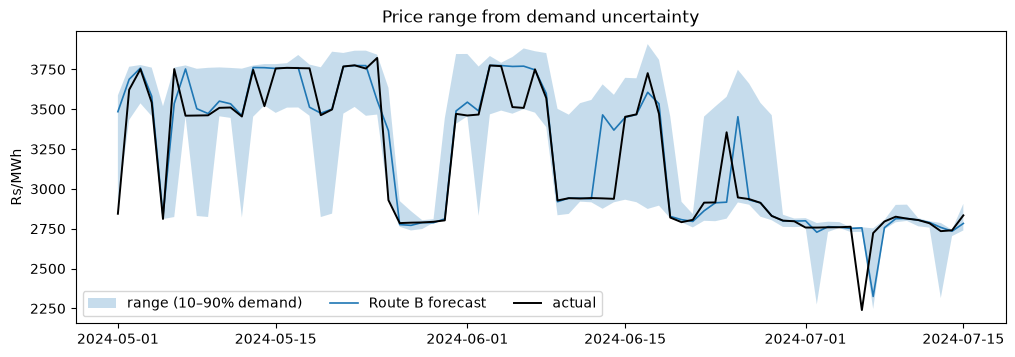

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.8))
window = slice("2024-05-01", "2024-07-15")
ax.fill_between(low.loc[window].index, low.loc[window], high.loc[window], alpha=0.25, label="range (10–90% demand)")
ax.plot(mid.loc[window], lw=1.2, label="Route B forecast"); ax.plot(truth.loc[window], color="black", lw=1.4, label="actual")
ax.set_ylabel("Rs/MWh"); ax.legend(ncol=3); ax.set_title("Price range from demand uncertainty")
plt.show()

## 6. Tightness (for Part 3)

In [11]:
avail_act = fc.available_capacity(gen, act_avail[act_avail.Date.between(SCORE.start, SCORE.stop)], dates)[states]
avail_fc = fc.available_capacity(gen, best_avail[best_avail.Date.between(SCORE.start, SCORE.stop)], dates)[states]
tight_act = fc.tightness(avail_act, demand_act)
tight_fc = fc.tightness(avail_fc, demand_fc)
nat_tight_act = (avail_act.sum(axis=1) - demand_act.sum(axis=1)) / demand_act.sum(axis=1)
nat_tight_fc = (avail_fc.sum(axis=1) - demand_fc.sum(axis=1)) / demand_fc.sum(axis=1)

print(f"India tightness: actual {nat_tight_act.mean():.1%} spare on average (min {nat_tight_act.min():.1%}); "
      f"forecast error {(nat_tight_fc - nat_tight_act).abs().mean():.2%} points")
bins = pd.qcut(nat_tight_fc, 5, labels=["tightest 20%", "2", "3", "4", "loosest 20%"])
jump = (truth - persistence).abs() >= fc.JUMP_RS
pd.DataFrame({"spare capacity (forecast)": nat_tight_fc.groupby(bins, observed=True).mean(),
              "actual price": truth.groupby(bins, observed=True).mean(),
              "share of days with a jump": jump.groupby(bins, observed=True).mean()}).round(3)

India tightness: actual 21.9% spare on average (min 4.5%); forecast error 1.81% points


,spare capacity (forecast),actual price,share of days with a jump
tightest 20%,0.092,3708.256,0.162
2,0.140,3495.803,0.342
3,0.196,3014.275,0.316
4,0.266,2789.056,0.025
loosest 20%,0.376,2652.839,0.253


## 7. Save

In [12]:
rows = []
for name, nat in runs.items():
    rows.append(pd.DataFrame({"Date": nat.index, "Area": "National", "Route": "B", "Run": name,
                              "Forecast": nat.to_numpy()}))
    rows.append(state_runs[name].stack().rename("Forecast").reset_index().rename(columns={"State": "Area"})
                .assign(Route="B", Run=name))
for (level, name), p in a_preds.items():
    if level == "National":
        rows.append(pd.DataFrame({"Date": p.index, "Area": "National", "Route": "A", "Run": name, "Forecast": p.to_numpy()}))
    else:
        rows.append(p.stack().rename("Forecast").reset_index().rename(columns={"State": "Area"}).assign(Route="A", Run=f"states {name}"))
out = pd.concat(rows, ignore_index=True)
out = out[out.Date.between(SCORE.start, SCORE.stop)]
actual_long = pd.concat([price.loc[SCORE].stack().rename("Actual").reset_index().rename(columns={"State": "Area"}),
                         truth.rename("Actual").reset_index().assign(Area="National")])
out = out.merge(actual_long, on=["Date", "Area"])
lo_hi = pd.concat([pd.DataFrame({"Low": low, "High": high}).assign(Area="National").rename_axis("Date").reset_index(),
                   pd.concat({"Low": np.minimum(band[0.1][1], band[0.9][1]).stack(),
                              "High": np.maximum(band[0.1][1], band[0.9][1]).stack()}, axis=1)
                     .rename_axis(["Date", "Area"]).reset_index()])
out = out.merge(lo_hi.assign(Route="B", Run="realistic"), on=["Date", "Area", "Route", "Run"], how="left")
tight = pd.concat([pd.concat({"Tightness_forecast": tight_fc.stack(), "Tightness_actual": tight_act.stack()}, axis=1)
                     .rename_axis(["Date", "Area"]).reset_index(),
                   pd.DataFrame({"Tightness_forecast": nat_tight_fc, "Tightness_actual": nat_tight_act})
                     .assign(Area="National").rename_axis("Date").reset_index()])
out = out.merge(tight, on=["Date", "Area"], how="left")
out.to_csv(PROCESSED / "price_forecast_test.csv", index=False, float_format="%.4f")
print(f"saved {len(out):,} rows: {out.groupby(['Route', 'Run']).ngroups} route-runs, {out.Area.nunique()} areas")

saved 92,268 rows: 11 route-runs, 33 areas


## Conclusions

**Route B (forecasts → dispatch) works; Route A (price from its own history) does not.** Mar 2024 – Mar 2025, national demand-weighted price:

| | National MAE | Skill | Jumps caught | Precision |
|---|---|---|---|---|
| Persistence (today's price) | 132 Rs/MWh | 0 | 0 / 87 | — |
| **Route B realistic** | **63 Rs/MWh** | **0.53** ✅ | **58 / 87 (67%)** | **73%** |
| Route A best (national LightGBM median) | 127 | 0.04 | 0 / 87 | — |
| Route A states (pooled LightGBM) | 156 | −0.18 | 34 / 87 | 37% |

- **The target (skill ≥ 0.20) is met by Route B, at national and state level** (state skill 0.51–0.54 in every state: trade links the prices, so all states share most of the error)
- **Route A can't see the steps.** Price history, calendar and weather say nothing about *where* the next coal-tier step is; the median model just learns "no change" (it calls no jumps), the mean model calls jumps at random (precision 37–46%). For a stepped price, the structural model is necessary
- **Route B sees most jumps coming:** two in three real jumps (≥ 200 Rs/MWh) are forecast in the right direction, and three in four forecast jumps happen. RMSE falls from 247 to 146: the big misses shrink most

**Which forecast error matters more?** With only the demand forecast wrong, MAE is 48 Rs/MWh; with only the availability forecast wrong, 38. **Demand error costs more**, but supply error is close behind (wind is the largest part, Stage 4). Together they give 63, less than 48 + 38: the errors partly cancel.

**Ranges:** dispatching the 10% and 90% demand forecasts gives an average range of 351 Rs/MWh that contains the actual price on 93% of days (wider than 80%, because a price stays on its step for a range of demand). On average the downside (195) is as large as the upside (156), so my expectation of a mostly upward-lopsided risk was wrong; but on **20% of days the upside is more than twice the downside**: those are the days just below a step.

**Tightness (for Part 3):** India has 22% spare available capacity on an average day (tightest day 4.5%), and the forecast tightness is within 1.8 percentage points. Price rises steadily as spare capacity falls: Rs 2,653/MWh in the loosest fifth of days, **Rs 3,708 in the tightest**. Jumps are most frequent in the *middle* (32–34% of days), where demand sits near a coal-tier step, not on the tightest days, which are already on the top step.

**For Part 3:** Route B gives bidders a usable view of tomorrow: the price within ~63 Rs/MWh on a typical day, most jumps flagged, and a tightness index that tracks the price level. Strategic bidding should matter most on tight days (high price, little spare capacity) and near the steps.

**Limitations:** the "actual" price is our dispatch model, so Route B uses the true price-setting mechanism while Route A has to learn it; with real market prices (IEX) Route B would also carry model error. 13 scored months. Route A uses the same LightGBM settings as demand, not re-tuned for prices.